# BRIGHT DFC2025 — Controllo dei dati e delle suddivisioni

## Obiettivo

Questo notebook verifica le liste ufficiali degli esempi utilizzati
nel Data Fusion Contest 2025, Track 2, e la disponibilità locale
dei file corrispondenti.

Controlliamo:
- numero di esempi e identificativi distinti in ciascuna lista;
- eventuali identificativi condivisi tra liste diverse;
- distribuzione degli esempi per evento;
- presenza sul computer di immagini ottiche, SAR e maschere.

Non eseguiamo un modello e non calcoliamo metriche sulle previsioni.

## Significato delle liste

Secondo il README delle suddivisioni ufficiali:

- `train_set.txt`: esempi con etichette visibili destinati all'addestramento;
- `holdout_set.txt`: esempi anch'essi con etichette visibili e destinati
  all'addestramento. Il nome holdout non indica qui automaticamente
  un insieme di valutazione;
- `val_set.txt`: esempi utilizzati per la valutazione durante lo sviluppo
  nella competizione, con etichette nascoste ai partecipanti;
- `test_set.txt`: esempi di due nuovi eventi utilizzati per la classifica finale.

Questo notebook controlla le liste e i file presenti localmente.
Non verifica la disponibilità remota delle etichette di validation e test.

Le etichette vere del test sono riservate alla valutazione finale.
L'eventuale utilizzo delle immagini di test senza etichette per generare
pseudo-label sarà definito in base al protocollo da riprodurre.

Essere presenti in una lista non significa essere già scaricati:
la disponibilità locale viene misurata nella sezione 4.

## 1. Lettura delle liste ufficiali

Leggiamo gli identificativi dalle quattro liste, eliminando
eventuali righe vuote e spazi iniziali o finali.

Conserviamo ciascuna lista in un dizionario chiamato `split`.
Per esempio, `split["train"]` conterrà gli identificativi di training.

Contiamo sia le voci totali sia gli identificativi distinti:
una differenza tra i due conteggi segnala duplicati interni.

Questo passaggio non verifica ancora le sovrapposizioni
tra liste diverse.

In [1]:
from pathlib import Path
import sys

PROGETTO = Path.cwd()

CARTELLA_SPLIT = (
    PROGETTO
    / "BRIGHT"
    / "bda_benchmark"
    / "dataset"
    / "splitname"
    / "dfc25"
)

CARTELLA_DATI = PROGETTO / "dati" / "bright_esempi"

print("Python utilizzato:", sys.executable)
print("Cartella di lavoro:", PROGETTO)

if not CARTELLA_SPLIT.is_dir():
    raise FileNotFoundError(
        "Cartella delle suddivisioni non trovata. "
        "Apri il notebook dalla cartella riproduzione_dfc2025."
    )

split = {}

for nome in ["train", "holdout", "val", "test"]:
    percorso = CARTELLA_SPLIT / f"{nome}_set.txt"

    righe = percorso.read_text(encoding="utf-8").splitlines()
    identificativi = [      # list comprehension: per ogni riga, togli gli spazi iniziali e finali e aggiungi alla lista solo se la riga non è vuota
        riga.strip()
        for riga in righe
        if riga.strip()
    ]

    split[nome] = identificativi

    numero_totale = len(identificativi)
    numero_distinti = len(set(identificativi))
    duplicati = numero_totale - numero_distinti

    print(
        f"\n{nome}: "
        f"{numero_totale} esempi, "
        f"{numero_distinti} distinti, "
        f"{duplicati} ripetizioni"
    )

Python utilizzato: /Users/antonyogrossi/tesi/venv-tesi/bin/python
Cartella di lavoro: /Users/antonyogrossi/tesi/riproduzione_dfc2025

train: 2229 esempi, 2229 distinti, 0 ripetizioni

holdout: 661 esempi, 661 distinti, 0 ripetizioni

val: 349 esempi, 349 distinti, 0 ripetizioni

test: 156 esempi, 156 distinti, 0 ripetizioni


## 2. Sovrapposizioni tra le suddivisioni

Confrontiamo le quattro liste a coppie per verificare se condividono
identificativi.

Per esempio, un identificativo presente sia nel training sia nel test
indicherebbe che lo stesso esempio è assegnato a entrambi i gruppi:
una situazione da chiarire prima degli esperimenti.

Utilizziamo l'intersezione tra insiemi, che restituisce gli elementi
presenti in entrambe le liste.

Questo controllo riguarda gli identificativi. L'assenza di nomi
condivisi non dimostra, da sola, che immagini con nomi diversi
non coprano aree geografiche sovrapposte.

In [2]:
from itertools import combinations

# Creiamo un insieme di identificativi per ogni suddivisione
insiemi_split = {
    nome: set(identificativi)
    for nome, identificativi in split.items()
}

trovate_sovrapposizioni = False

# Confrontiamo tutte le coppie, senza ripeterle
for nome_a, nome_b in combinations(insiemi_split, 2):
    comuni = insiemi_split[nome_a] & insiemi_split[nome_b]

    print(f"{nome_a} / {nome_b}: {len(comuni)} identificativi comuni")

    if comuni:
        trovate_sovrapposizioni = True
        print("  Primi identificativi comuni:", sorted(comuni)[:5])

# Uniamo tutte le liste, contando ogni identificativo una sola volta
tutti_identificativi = set().union(*insiemi_split.values())

totale_voci = sum(len(lista) for lista in split.values())

print("\nTotale delle voci nelle quattro liste:", totale_voci)
print("Identificativi distinti complessivi:", len(tutti_identificativi))

if trovate_sovrapposizioni:
    print("\nSono presenti sovrapposizioni da approfondire.")
else:
    print("\nNessun identificativo condiviso tra le quattro liste.")

import pandas as pd

# Registriamo le sovrapposizioni per riutilizzarle nei controlli e nei CSV.
righe_sovrapposizioni = []

for nome_a, nome_b in combinations(insiemi_split, 2):
    comuni = insiemi_split[nome_a] & insiemi_split[nome_b]

    for identificativo in sorted(comuni):
        righe_sovrapposizioni.append({
            "split_a": nome_a,
            "split_b": nome_b,
            "id": identificativo,
        })

sovrapposizioni = pd.DataFrame(
    righe_sovrapposizioni,
    columns=["split_a", "split_b", "id"],
)

display(sovrapposizioni)

train / holdout: 1 identificativi comuni
  Primi identificativi comuni: ['bata-explosion_00000049']
train / val: 1 identificativi comuni
  Primi identificativi comuni: ['libya-flood_00000024']
train / test: 0 identificativi comuni
holdout / val: 0 identificativi comuni
holdout / test: 0 identificativi comuni
val / test: 0 identificativi comuni

Totale delle voci nelle quattro liste: 3395
Identificativi distinti complessivi: 3393

Sono presenti sovrapposizioni da approfondire.


,split_a,split_b,id
0,train,holdout,bata-explosion_00000049
1,train,val,libya-flood_00000024


In [3]:
da_verificare = set(sovrapposizioni["id"])

for nome in ["train", "holdout", "val", "test"]:
    percorso = CARTELLA_SPLIT / f"{nome}_set.txt"

    for numero_riga, riga in enumerate(
        percorso.read_text(encoding="utf-8").splitlines(),
        start=1,
    ):
        if riga.strip() in da_verificare:
            print(f"{percorso.name}, riga {numero_riga}: {riga.strip()}")

train_set.txt, riga 1: bata-explosion_00000049
train_set.txt, riga 312: libya-flood_00000024
holdout_set.txt, riga 17: bata-explosion_00000049
val_set.txt, riga 65: libya-flood_00000024


### Interpretazione delle sovrapposizioni

La tabella precedente riporta gli identificativi condivisi tra le liste.

Una condivisione tra train e holdout richiede di evitare duplicazioni
qualora questi insiemi vengano uniti per l'addestramento.

Una condivisione tra train e validation richiede invece una decisione
esplicita prima di addestrare e valutare il modello, per evitare
che lo stesso esempio compaia in entrambe le fasi.

Le liste originali vengono conservate inalterate.
Prima degli esperimenti definiremo eventuali liste operative separate,
documentando le esclusioni e verificando il protocollo della soluzione
che intendiamo riprodurre.

## 3. Distribuzione degli esempi per evento

Ogni identificativo contiene il nome dell'evento e un numero finale.

Per esempio:
`bata-explosion_00000049`

Separando l'identificativo all'ultimo underscore otteniamo:
- evento: `bata-explosion`;
- numero dell'esempio: `00000049`.

Contiamo gli esempi di ciascun evento nelle quattro suddivisioni.
Questo permette di capire come sono distribuiti i dati e quali
eventi sono presenti nel test.

I conteggi riguardano esempi di immagini, non edifici o pixel.
Le liste originali vengono utilizzate senza rimuovere le
sovrapposizioni già documentate.

In [4]:
from collections import Counter
import pandas as pd

conteggi_eventi = {}

for nome_split, identificativi in split.items():
    eventi = [
        identificativo.rsplit("_", 1)[0]
        for identificativo in identificativi
    ]

    conteggi_eventi[nome_split] = Counter(eventi)

tabella_eventi = (
    pd.DataFrame(conteggi_eventi)
    .fillna(0)
    .astype(int)
    .sort_index()
)

tabella_eventi = tabella_eventi[["train", "holdout", "val", "test"]]

display(tabella_eventi)

print("Totali per suddivisione:")
print(tabella_eventi.sum())

,train,holdout,val,test
bata-explosion,70,23,14,0
beirut-explosion,89,27,17,0
congo-volcano,81,27,15,0
haiti-earthquake,48,15,10,0
hawaii-wildfire,42,14,9,0
la_palma-volcano,647,189,97,0
libya-flood,83,26,15,0
marshall-wildfire,0,0,0,77
morocco-earthquake,392,116,59,0
noto-earthquake,0,0,0,79


Totali per suddivisione:
train      2229
holdout     661
val         349
test        156
dtype: int64


### Interpretazione della distribuzione per evento

La tabella precedente mostra quanti esempi di ciascun evento appartengono
alle diverse suddivisioni.

Permette di riconoscere gli eventi presenti nel test e confrontarli
con quelli delle altre liste, oltre a osservare eventuali squilibri
nel numero di immagini disponibili.

I totali si riferiscono alle liste originali, senza rimuovere
le sovrapposizioni rilevate.

## 4. Disponibilità locale dei file

Per ogni identificativo delle quattro liste cerchiamo:

- l'immagine ottica nella cartella `pre-event`;
- l'immagine SAR nella cartella `post-event`;
- la maschera del danno nella cartella `target`.

Un esempio viene considerato completo quando tutti e tre i file
sono presenti nella cartella `dati/bright_esempi`.

Il controllo verifica soltanto l'esistenza dei file:
non ne legge il contenuto e non ne verifica l'integrità.

Un file assente da questa cartella non è necessariamente
non disponibile online: può semplicemente non essere stato scaricato.

Lo stesso identificativo presente in due liste viene controllato
in entrambe, anche se corrisponde agli stessi file sul disco.

In [5]:
if not CARTELLA_DATI.is_dir():
    raise FileNotFoundError(
        f"Cartella dei dati non trovata: {CARTELLA_DATI}"
    )

controlli = []

for nome_split, identificativi in split.items():
    for identificativo in identificativi:

        percorso_ottico = (
            CARTELLA_DATI / "pre-event"
            / f"{identificativo}_pre_disaster.tif"
        )
        percorso_sar = (
            CARTELLA_DATI / "post-event"
            / f"{identificativo}_post_disaster.tif"
        )
        percorso_maschera = (
            CARTELLA_DATI / "target"
            / f"{identificativo}_building_damage.tif"
        )

        controlli.append({
            "split": nome_split,
            "id": identificativo,
            "ottico_presente": percorso_ottico.is_file(),
            "sar_presente": percorso_sar.is_file(),
            "maschera_presente": percorso_maschera.is_file(),
        })

disponibilita = pd.DataFrame(controlli)

colonne_file = [
    "ottico_presente",
    "sar_presente",
    "maschera_presente",
]

disponibilita["completo"] = disponibilita[colonne_file].all(axis=1)

riepilogo = (
    disponibilita.groupby("split")
    .agg(
        esempi_in_lista=("id", "size"),
        ottici_presenti=("ottico_presente", "sum"),
        sar_presenti=("sar_presente", "sum"),
        maschere_presenti=("maschera_presente", "sum"),
        esempi_completi=("completo", "sum"),
    )
    .reindex(["train", "holdout", "val", "test"])
)

display(riepilogo)

print("Esempi completi e rispettive suddivisioni:")
display(
    disponibilita.loc[
        disponibilita["completo"],
        ["split", "id"]
    ]
)

,esempi_in_lista,ottici_presenti,sar_presenti,maschere_presenti,esempi_completi
split,,,,,
train,2229,3,3,3,3
holdout,661,1,1,1,1
val,349,0,0,0,0
test,156,0,0,0,0


Esempi completi e rispettive suddivisioni:


,split,id
0,train,bata-explosion_00000049
1,train,bata-explosion_00000014
2,train,bata-explosion_00000047
2245,holdout,bata-explosion_00000049


### Interpretazione della verifica locale

Il riepilogo indica quanti esempi dispongono dei file richiesti
nella cartella controllata.

Lo stesso identificativo può essere conteggiato in più suddivisioni
se compare in più liste, pur corrispondendo agli stessi file sul disco.
Nell'analisi delle maschere ogni identificativo sarà considerato una sola volta.

Un conteggio nullo indica assenza nella cartella controllata:
non dimostra che i file siano indisponibili online.

## 5. Distribuzione delle classi nel campione locale

Contiamo i pixel delle quattro classi nelle maschere degli esempi
completi presenti sul computer:

- 0: sfondo;
- 1: edificio integro;
- 2: edificio danneggiato;
- 3: edificio distrutto.

Analizziamo ogni identificativo completo una sola volta, anche se compare
in più suddivisioni.

Calcoliamo i pixel per classe in ogni maschera e nell'insieme delle
maschere locali analizzate. Le percentuali includono lo sfondo
ed escludono i pixel non validi.

In [6]:
import numpy as np
import rasterio

classi = {
    0: "Sfondo",
    1: "Edificio integro",
    2: "Edificio danneggiato",
    3: "Edificio distrutto",
}

# Selezioniamo gli esempi completi senza ripetere gli identificativi
id_locali = (
    disponibilita.loc[disponibilita["completo"], "id"]
    .drop_duplicates()
    .tolist()
)

if not id_locali:
    raise ValueError("Nessun esempio completo disponibile.")

righe_statistiche = []

for identificativo in id_locali:
    percorso = (
        CARTELLA_DATI / "target"
        / f"{identificativo}_building_damage.tif"
    )

    with rasterio.open(percorso) as dataset:
        maschera = dataset.read(1, masked=True)

    # Conserviamo soltanto i pixel validi.
    # Lo sfondo 0 resta incluso se non è dichiarato NoData.
    pixel_validi = maschera.compressed()

    valori, conteggi = np.unique(pixel_validi, return_counts=True)

    inattesi = set(valori.tolist()) - set(classi)
    if inattesi:
        raise ValueError(
            f"{identificativo}: etichette inattese {inattesi}"
        )

    conteggi_per_classe = dict(zip(valori.tolist(), conteggi.tolist()))

    riga = {"id": identificativo}

    for codice, descrizione in classi.items():
        riga[descrizione] = conteggi_per_classe.get(codice, 0)

    righe_statistiche.append(riga)

statistiche_locali = pd.DataFrame(righe_statistiche).set_index("id")

print("Pixel per classe in ciascun esempio:")
display(statistiche_locali)

# Sommiamo i conteggi di tutte le maschere analizzate
totali_classi = statistiche_locali.sum(axis=0)
totale_pixel = int(totali_classi.sum())

if totale_pixel == 0:
    raise ValueError("Le maschere non contengono pixel validi.")

riepilogo_classi = pd.DataFrame({
    "pixel": totali_classi,
    "percentuale": 100 * totali_classi / totale_pixel,
})

print("Distribuzione complessiva del campione locale:")
display(riepilogo_classi.round(2))

print("Esempi distinti analizzati:", len(id_locali))
print("Totale pixel validi:", totale_pixel)

Pixel per classe in ciascun esempio:


,Sfondo,Edificio integro,Edificio danneggiato,Edificio distrutto
id,,,,
bata-explosion_00000049,919216,6789,20426,102145
bata-explosion_00000014,963932,84644,0,0
bata-explosion_00000047,913622,134954,0,0


Distribuzione complessiva del campione locale:


,pixel,percentuale
Sfondo,2796770,88.91
Edificio integro,226387,7.20
Edificio danneggiato,20426,0.65
Edificio distrutto,102145,3.25


Esempi distinti analizzati: 3
Totale pixel validi: 3145728


### Interpretazione delle statistiche

La tabella mostra la distribuzione dei pixel tra le classi.

Una previsione che assegna sempre la classe sfondo avrebbe
un'accuratezza pari alla percentuale di pixel di sfondo riportata
nella tabella, senza riconoscere alcun edificio.

Questo spiega perché l'accuratezza complessiva, da sola, non basta:
occorre valutare anche il comportamento sulle singole classi.

## 6. Maschere binarie: edificio e sfondo

Deriviamo dalle maschere del danno una versione binaria:

- 0: sfondo;
- 1: edificio, indipendentemente dalla categoria di danno.

Poiché abbiamo verificato che le etichette presenti sono 0, 1, 2 e 3,
possiamo usare la condizione `maschera > 0`.

Conserviamo l'eventuale maschera di validità ed escludiamo
i pixel non validi dai conteggi.

Le maschere binarie vengono create in memoria:
non modifichiamo i TIFF originali.

Sono etichette di riferimento derivate dalle annotazioni,
non footprint previsti da un modello. Possono servire per
addestrare o valutare un modello di estrazione degli edifici.

Non devono essere presentate come output della prima fase
dei vincitori.

In [7]:
maschere_binarie = {}
righe_binarie = []

for identificativo in id_locali:
    percorso = (
        CARTELLA_DATI / "target"
        / f"{identificativo}_building_damage.tif"
    )

    with rasterio.open(percorso) as dataset:
        maschera = dataset.read(1, masked=True)

    # 0 resta sfondo; 1, 2 e 3 diventano edificio
    binaria = (maschera > 0).astype(np.uint8)
    maschere_binarie[identificativo] = binaria

    pixel_validi = binaria.compressed()

    numero_sfondo = int(np.count_nonzero(pixel_validi == 0))
    numero_edificio = int(np.count_nonzero(pixel_validi == 1))
    totale = numero_sfondo + numero_edificio

    righe_binarie.append({
        "id": identificativo,
        "pixel_sfondo": numero_sfondo,
        "pixel_edificio": numero_edificio,
        "percentuale_edificio": (
            100 * numero_edificio / totale if totale else np.nan
        ),
    })

statistiche_binarie = pd.DataFrame(righe_binarie).set_index("id")
display(statistiche_binarie.round(2))

totale_sfondo = int(statistiche_binarie["pixel_sfondo"].sum())
totale_edificio = int(statistiche_binarie["pixel_edificio"].sum())
totale = totale_sfondo + totale_edificio

print("Pixel sfondo complessivi:", totale_sfondo)
print("Pixel edificio complessivi:", totale_edificio)
print(f"Percentuale edificio complessiva: {100 * totale_edificio / totale:.2f}%")

,pixel_sfondo,pixel_edificio,percentuale_edificio
id,,,
bata-explosion_00000049,919216,129360,12.34
bata-explosion_00000014,963932,84644,8.07
bata-explosion_00000047,913622,134954,12.87


Pixel sfondo complessivi: 2796770
Pixel edificio complessivi: 348958
Percentuale edificio complessiva: 11.09%


### Risultato della conversione binaria

I pixel delle classi integro, danneggiato e distrutto sono riuniti
nella categoria edificio, mantenendo le posizioni annotate.

I conteggi e le percentuali aggiornati sono riportati nell'output precedente.

## 7. Confronto visivo tra maschera del danno e maschera binaria

Visualizziamo due rappresentazioni delle stesse annotazioni:

- a sinistra, le quattro classi della maschera del danno;
- a destra, soltanto sfondo ed edificio.

Nella maschera binaria, gli edifici integri, danneggiati e distrutti
ricevono tutti lo stesso colore. Le sagome restano invariate;
viene eliminata soltanto la distinzione del danno.

Entrambe le immagini sono riferimenti derivati dalle annotazioni
del dataset, non previsioni di un modello.

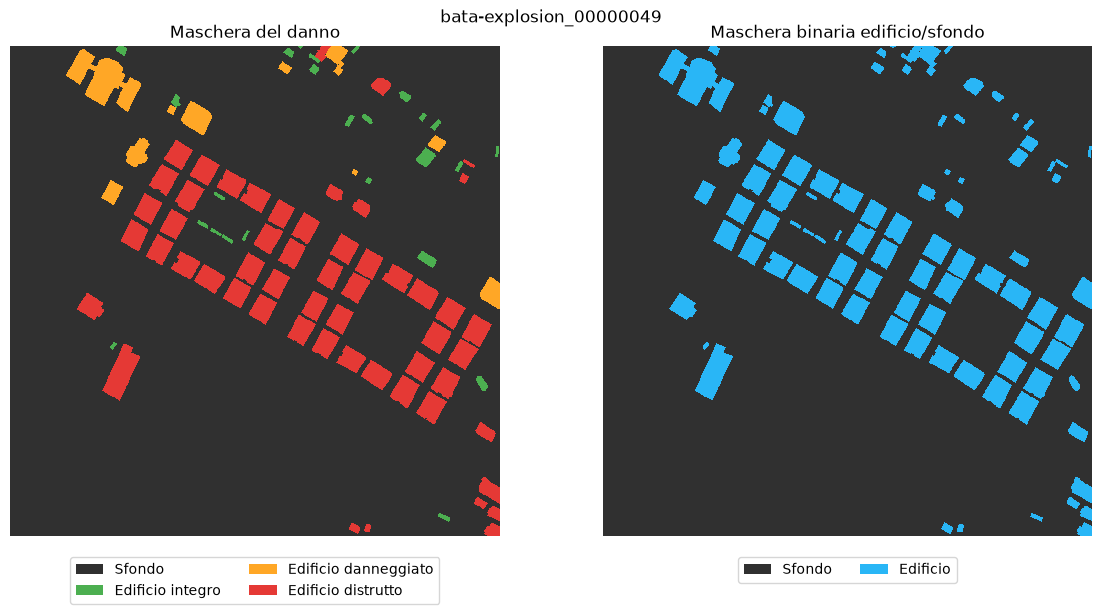

In [8]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

identificativo = "bata-explosion_00000049"

percorso = (
    CARTELLA_DATI / "target"
    / f"{identificativo}_building_damage.tif"
)

with rasterio.open(percorso) as dataset:
    danno = dataset.read(1, masked=True)

binaria = maschere_binarie[identificativo]

# Colori delle quattro classi di danno
colori_danno = ["#303030", "#4CAF50", "#FFA726", "#E53935"]
cmap_danno = ListedColormap(colori_danno)
cmap_danno.set_bad("#808080")
norm_danno = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], 4)

# Colori delle due classi binarie
colori_binari = ["#303030", "#29B6F6"]
cmap_binaria = ListedColormap(colori_binari)
cmap_binaria.set_bad("#808080")
norm_binaria = BoundaryNorm([-0.5, 0.5, 1.5], 2)

fig, assi = plt.subplots(1, 2, figsize=(12, 6))

assi[0].imshow(
    danno,
    cmap=cmap_danno,
    norm=norm_danno,
    interpolation="nearest",
)
assi[0].set_title("Maschera del danno")

assi[1].imshow(
    binaria,
    cmap=cmap_binaria,
    norm=norm_binaria,
    interpolation="nearest",
)
assi[1].set_title("Maschera binaria edificio/sfondo")

assi[0].legend(
    handles=[
        Patch(facecolor=colori_danno[codice], label=descrizione)
        for codice, descrizione in classi.items()
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.03),
    ncol=2,
)

assi[1].legend(
    handles=[
        Patch(facecolor=colori_binari[0], label="Sfondo"),
        Patch(facecolor=colori_binari[1], label="Edificio"),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.03),
    ncol=2,
)

for asse in assi:
    asse.axis("off")

fig.suptitle(identificativo)
plt.tight_layout()
plt.show()

## 8. Salvataggio dei risultati dei controlli

Salviamo in formato CSV:

- la distribuzione degli esempi per evento;
- la presenza dei file per ogni identificativo e suddivisione;
- il riepilogo della disponibilità locale;
- i conteggi delle classi nelle maschere locali analizzate;
- le statistiche della versione binaria edificio/sfondo;
- gli identificativi condivisi tra liste diverse.

Un CSV è una tabella di testo leggibile anche con programmi
come Excel o Google Sheets.

I risultati vengono salvati in `risultati/02_dati_e_split`.
Le liste originali e i TIFF non vengono modificati.

Le tabelle sulla disponibilità descrivono la situazione al momento
dell'esecuzione. Dopo nuovi download, occorre rieseguire i controlli
prima di salvarle nuovamente.

In [9]:
CARTELLA_RISULTATI = PROGETTO / "risultati" / "02_dati_e_split"
CARTELLA_RISULTATI.mkdir(parents=True, exist_ok=True)

# Tabelle con indice significativo: conserviamo anche l'indice
tabella_eventi.to_csv(
    CARTELLA_RISULTATI / "esempi_per_evento.csv",
    index_label="evento",
)
riepilogo.to_csv(
    CARTELLA_RISULTATI / "riepilogo_disponibilita.csv",
    index_label="split",
)
statistiche_locali.to_csv(
    CARTELLA_RISULTATI / "pixel_per_classe_per_esempio.csv",
    index_label="id",
)
riepilogo_classi.to_csv(
    CARTELLA_RISULTATI / "distribuzione_classi_locale.csv",
    index_label="classe",
)
statistiche_binarie.to_csv(
    CARTELLA_RISULTATI / "statistiche_binarie.csv",
    index_label="id",
)

# Qui gli identificativi sono già contenuti nelle colonne
disponibilita.to_csv(
    CARTELLA_RISULTATI / "disponibilita_per_esempio.csv",
    index=False,
)
sovrapposizioni.to_csv(
    CARTELLA_RISULTATI / "sovrapposizioni_split.csv",
    index=False,
)

print("Tabelle salvate in:", CARTELLA_RISULTATI)

for percorso in sorted(CARTELLA_RISULTATI.glob("*.csv")):
    print("-", percorso.name)

Tabelle salvate in: /Users/antonyogrossi/tesi/riproduzione_dfc2025/risultati/02_dati_e_split
- disponibilita_per_esempio.csv
- distribuzione_classi_locale.csv
- esempi_per_evento.csv
- pixel_per_classe_per_esempio.csv
- riepilogo_disponibilita.csv
- sovrapposizioni_split.csv
- statistiche_binarie.csv


## 9. Conclusioni

### Risultati prodotti

Il notebook controlla gli identificativi delle suddivisioni ufficiali,
le loro sovrapposizioni, la distribuzione per evento e la disponibilità
locale dei file.

Per gli esempi completi presenti nella cartella analizzata, calcola
la distribuzione delle classi e deriva maschere binarie edificio/sfondo.

I risultati numerici aggiornati sono riportati nelle tabelle generate
dal codice e salvati in `risultati/02_dati_e_split`.

Le liste originali e i TIFF non vengono modificati.

### Decisioni prima dell'addestramento

Prima degli esperimenti sarà necessario definire come utilizzare
train e holdout, evitare duplicazioni nell'eventuale insieme unito
e risolvere le condivisioni tra addestramento e validation.

Le decisioni saranno documentate in liste operative separate,
tenendo conto del protocollo della soluzione da riprodurre.

L'eventuale utilizzo delle immagini di test senza etichette per
generare pseudo-label dovrà essere dichiarato esplicitamente.
Le etichette vere del test resteranno riservate alla valutazione finale.

### Limiti

- Le statistiche delle classi riguardano soltanto le maschere locali
  analizzate e contano pixel, non singoli edifici. Non descrivono
  automaticamente l'intero dataset.
- Prima di utilizzare queste frequenze per impostare l'addestramento,
  occorre estendere l'analisi alle maschere dell'intero insieme
  di training effettivamente adottato.
- Il controllo di disponibilità verifica la presenza dei file nella
  cartella indicata, non la loro integrità né la disponibilità online.
- Il confronto degli identificativi non rileva eventuali sovrapposizioni
  geografiche tra immagini con nomi diversi.
- Le maschere binarie sono derivate dalle annotazioni di riferimento:
  non sono previsioni di un modello.
- Le percentuali arrotondate possono non sommare esattamente a 100%.

Non abbiamo eseguito un modello, addestrato una rete o misurato
prestazioni predittive.

### Passaggio successivo

Nel notebook 03 esamineremo le metriche di valutazione, verificandone
il calcolo su piccoli esempi controllati e confrontandolo con il codice
di riferimento.